# ARGus v2 · Random Forest k = 6 + Random Undersampling · positivos a 90 % de identidad

Protocolo de la reunión del 18-oct:
1. Submuestrear **solo los negativos** (Random Undersampling) dentro del entrenamiento.
2. Tomar **todos los positivos** del entrenamiento.
3. Entrenar el Random Forest (k = 6).
4. Evaluar en un **test separado por gen** (distribución natural, sin balancear).
5. Guardar el modelo (joblib).
6. Evaluar el modelo guardado en los **1k + 1k genes** y comparar con ARGus v1, ARGNet y DeepARG.

**Fuga de datos:** los 2000 genes del 1k+1k se excluyen del entrenamiento y del test.

Este cuaderno es el de **90 %**. Hay otros dos idénticos (95, 90, 85): solo cambian `POSITIVOS_FILTRO` y `ETIQUETA_CORRIDA` en la celda 1.
Ejecutar de arriba hacia abajo (Run All).

In [ ]:
# ============ CELDA 1: configuración ============
import re, time, json, joblib
from pathlib import Path
import numpy as np, pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (recall_score, precision_score, f1_score,
                             roc_auc_score, confusion_matrix)

# Carpeta data/interim. Si esta ruta no existe, busca sola dentro de /mnt/c/Users y del home.
INTERIM_MANUAL = "/mnt/c/Users/r4gbi/Desktop/Proyecto_Residencias/data/interim"
INTERIM = Path(INTERIM_MANUAL)
if not (INTERIM / "dataset_fragmentado_500.tsv").exists():
    hits = []
    for raiz in (Path("/mnt/c/Users"), Path.home()):
        if raiz.exists(): hits += list(raiz.rglob("dataset_fragmentado_500.tsv"))
    assert hits, "No encontré dataset_fragmentado_500.tsv: corrige INTERIM_MANUAL"
    INTERIM = hits[0].parent
print("INTERIM =", INTERIM)

DATASET_FRAG  = INTERIM / "dataset_fragmentado_500.tsv"       # id / lectura / etiqueta
DATASET_GENES = INTERIM / "dataset_etiquetado_completo.tsv"
SET_1K1K      = INTERIM / "muestra_genes_labels.tsv"          # los 2000 genes de comparación
FASTA_1K1K    = INTERIM / "muestra_genes_completos.fasta"

POSITIVOS_FILTRO = INTERIM / "positivo_id90_limpio.fasta"      # None = set de 95 %
ETIQUETA_CORRIDA = "id90"
PCT = "90"

K = 6                              # indicación de la asesora
VENTANA = 500
SEED = 42
FRAC_TEST = 0.10                   # 1 de cada 10 grupos (StratifiedGroupKFold con 10 pliegues)
N_ARBOLES = 200
SALIDA = INTERIM.parent / "models"; SALIDA.mkdir(parents=True, exist_ok=True)
print("K =", K, "| columnas por fragmento:", 4**K, "| set de positivos:", PCT, "%")

INTERIM = /mnt/c/Users/r4gbi/Desktop/Proyecto_Residencias/data/interim
K = 6 | columnas por fragmento: 4096 | set de positivos: 90 %


In [ ]:
# ============ CELDA 2: cargar fragmentos, asignar gen y excluir los 2000 genes ============
frag = pd.read_csv(DATASET_FRAG, sep="\t")
print(frag.shape); print(frag.head(3))

col_id, col_seq, col_lab = "id", "lectura", "etiqueta"
assert {col_id, col_seq, col_lab} <= set(frag.columns), f"columnas encontradas: {list(frag.columns)}"
frag[col_lab] = frag[col_lab].astype(int)

# el gen es el id sin el sufijo "__fragN"
frag["gen"] = frag[col_id].str.replace(r"__frag\d+$", "", regex=True)
print("genes distintos:", frag["gen"].nunique(), "| fragmentos:", len(frag))

# --- excluir los 2000 genes del 1k+1k ---
lab1k = pd.read_csv(SET_1K1K, sep="\t")
ids_1k = set(lab1k.iloc[:, 0].astype(str))
genes_frag = set(frag["gen"])
excluir = ids_1k & genes_frag
faltan = ids_1k - excluir
if faltan:  # respaldo: probar sin el prefijo del genoma (GCF_...|)
    variantes = {}
    for g in genes_frag: variantes.setdefault(g.split("|", 1)[-1], g)
    for f in list(faltan):
        if f in variantes: excluir.add(variantes[f]); faltan.discard(f)
print("genes del 1k+1k encontrados en el dataset:", len(excluir), "de", len(ids_1k))
assert not faltan, f"No encontré genes del 1k+1k: {list(faltan)[:5]} | ejemplos de gen: {list(genes_frag)[:3]}"

mask_1k = frag["gen"].isin(excluir)
print("fragmentos excluidos:", mask_1k.sum())
print(frag[mask_1k].drop_duplicates("gen")[col_lab].value_counts())      # esperado: ~1000 y ~1000
pool = frag[~mask_1k].reset_index(drop=True)

# --- filtro opcional de positivos (90 % / 85 %) ---
if POSITIVOS_FILTRO is not None:
    hdrs = [l[1:].strip() for l in open(POSITIVOS_FILTRO) if l.startswith(">")]
    ids_ok = set(hdrs) | {h.split()[0] for h in hdrs}
    pos_genes = set(pool.loc[pool[col_lab] == 1, "gen"])
    # secuencias del set filtrado que NO son del 1k+1k (esas ya se sacaron del pool a propósito)
    esperadas = [h for h in hdrs if h not in excluir and h.split()[0] not in excluir]
    casan = [h for h in esperadas if h in pos_genes or h.split()[0] in pos_genes]
    print(f"set filtrado: {len(hdrs)} secuencias | fuera del 1k+1k: {len(esperadas)} | casan con el dataset: {len(casan)}")
    assert len(casan) >= 0.9 * len(esperadas), ("Los ids del FASTA filtrado no casan con los genes del dataset; "
                                                f"ejemplo FASTA: {hdrs[0]} | ejemplo dataset: {next(iter(pos_genes))}")
    quitar = (pool[col_lab] == 1) & (~pool["gen"].isin(ids_ok))
    print("fragmentos positivos fuera del set filtrado (se quitan):", quitar.sum())
    pool = pool[~quitar].reset_index(drop=True)

print(pool[col_lab].value_counts().rename({0: "neg (frag)", 1: "pos (frag)"}))
print("genes positivos:", pool.loc[pool[col_lab] == 1, "gen"].nunique(), "| genes negativos:", pool.loc[pool[col_lab] == 0, "gen"].nunique())

(72874, 3)
                                                  id  \
0  CARD|gb|AF028812.1|+|392-887|ARO:3002867|dfrF_...   
1  CARD|gb|AY234334.1|+|0-846|ARO:3000600|Erm(34)...   
2  CARD|gb|AY234334.1|+|0-846|ARO:3000600|Erm(34)...   

                                             lectura  etiqueta  
0  ATGATAGGTTTGATTGTTGCGAGGTCAAAGAATAATGTTATAGGCA...         1  
1  ATGACGAAAAAAATGAACAAGTATAATGGGAAAAAACTTAGCCGTG...         1  
2  TGACATCCACTATGAAAGGGGAATTTCCAGAAGTTCATTTTCGCCG...         1  
genes distintos: 30741 | fragmentos: 72874
genes del 1k+1k encontrados en el dataset: 2000 de 2000
fragmentos excluidos: 4667
etiqueta
1    1000
0    1000
Name: count, dtype: int64
set filtrado: 3762 secuencias | fuera del 1k+1k: 2879 | casan con el dataset: 2853
fragmentos positivos fuera del set filtrado (se quitan): 843
etiqueta
neg (frag)    60978
pos (frag)     6386
Name: count, dtype: int64
genes positivos: 2853 | genes negativos: 25513


In [ ]:
# ============ CELDA 3: k-mers rápidos (vectorizado) ============
LUT = np.full(256, 4, dtype=np.int8)
for i, b in enumerate(b"ACGT"): LUT[b] = i
POT = (4 ** np.arange(K - 1, -1, -1)).astype(np.int64)

def vector_kmer(seq):
    # frecuencia relativa de los 4^K k-mers; ventanas con '0' (relleno) u otra base se ignoran
    a = LUT[np.frombuffer(seq.upper().encode(), dtype=np.uint8)]
    n = len(a) - K + 1
    out = np.zeros(4 ** K, dtype=np.float32)
    if n <= 0: return out
    win = np.lib.stride_tricks.sliding_window_view(a, K)
    ok = (win < 4).all(axis=1)
    if not ok.any(): return out
    idx = (win[ok].astype(np.int64) * POT).sum(axis=1)
    out += np.bincount(idx, minlength=4 ** K).astype(np.float32)
    return out / out.sum()

def matriz(seqs):
    X = np.empty((len(seqs), 4 ** K), dtype=np.float32)
    for i, s in enumerate(seqs): X[i] = vector_kmer(s)
    return X

print(vector_kmer("ACGT" * 10 + "0" * 20).sum())   # prueba: debe ser 1.0

1.0


In [ ]:
# ============ CELDA 4: partición por gen (train / test) y Random Undersampling SOLO en train ============
y_all = pool[col_lab].values
g_all = pool["gen"].values

sgkf = StratifiedGroupKFold(n_splits=int(round(1 / FRAC_TEST)), shuffle=True, random_state=SEED)
tr, te = next(sgkf.split(np.zeros(len(y_all)), y_all, g_all))
assert not set(g_all[tr]) & set(g_all[te]), "FUGA: un gen aparece en train y test"

rng = np.random.default_rng(SEED)
pos = tr[y_all[tr] == 1]                                   # TODOS los positivos del train
neg = tr[y_all[tr] == 0]
neg_ds = rng.choice(neg, size=len(pos), replace=False)     # Random Undersampling (solo negativos)
tr_bal = np.concatenate([pos, neg_ds]); rng.shuffle(tr_bal)

print(f"train original : pos={len(pos):,}  neg={len(neg):,}  (razón {len(neg)/len(pos):.1f}:1)")
print(f"train balanceado: pos={len(pos):,}  neg={len(neg_ds):,}")
print(f"test (natural) : pos={(y_all[te]==1).sum():,}  neg={(y_all[te]==0).sum():,}")

train original : pos=5,747  neg=54,880  (razón 9.5:1)
train balanceado: pos=5,747  neg=5,747
test (natural) : pos=639  neg=6,098


In [ ]:
# ============ CELDA 5: features (solo de lo necesario) y entrenamiento ============
t0 = time.time()
seqs = pool[col_seq].astype(str).values
X_tr = matriz(seqs[tr_bal]); y_tr = y_all[tr_bal]
print("X_train:", X_tr.shape, f"{X_tr.nbytes/1e9:.2f} GB", f"({time.time()-t0:.0f}s)")

rf = RandomForestClassifier(n_estimators=N_ARBOLES, n_jobs=-1, random_state=SEED)
rf.fit(X_tr, y_tr)
print(f"RF entrenado en {time.time()-t0:.0f}s")

X_train: (11494, 4096) 0.19 GB (1s)
RF entrenado en 9s


In [ ]:
# ============ CELDA 6: evaluación en el TEST (distribución natural) ============
X_te = matriz(seqs[te]); y_te = y_all[te]
p_te = rf.predict_proba(X_te)[:, 1]; pred_te = (p_te >= 0.5).astype(int)

def metricas(y, pred, p=None):
    d = dict(recall=recall_score(y, pred), precision=precision_score(y, pred, zero_division=0),
             f1=f1_score(y, pred))
    if p is not None: d["auc"] = roc_auc_score(y, p)
    return d

m_frag = metricas(y_te, pred_te, p_te)
print("== FRAGMENTO ==", {k: round(v, 3) for k, v in m_frag.items()})
print(confusion_matrix(y_te, pred_te))

# nivel gen: un gen es ARG si ALGÚN fragmento lo es
df_te = pd.DataFrame({"gen": g_all[te], "y": y_te, "pred": pred_te, "p": p_te})
gg = df_te.groupby("gen").agg(y=("y", "max"), pred=("pred", "max"), p=("p", "max"))
m_gen = metricas(gg.y, gg.pred, gg.p)
print("== GEN (any) ==", {k: round(v, 3) for k, v in m_gen.items()}, "| genes test:", len(gg))

== FRAGMENTO == {'recall': 0.72, 'precision': 0.317, 'f1': 0.44, 'auc': 0.861}
[[5107  991]
 [ 179  460]]
== GEN (any) == {'recall': 0.874, 'precision': 0.246, 'f1': 0.383, 'auc': 0.876} | genes test: 2837


In [ ]:
# ============ CELDA 7: guardar el modelo ============
ruta_modelo = SALIDA / f"argus_rf_k{K}_{ETIQUETA_CORRIDA}.joblib"
joblib.dump({"modelo": rf, "K": K, "ventana": VENTANA, "relleno": "0",
             "regla_gen": "any", "umbral": 0.5, "semilla": SEED,
             "metricas_test_fragmento": m_frag, "metricas_test_gen": m_gen}, ruta_modelo, compress=3)
print("guardado:", ruta_modelo, f"{ruta_modelo.stat().st_size/1e6:.0f} MB")

guardado: /mnt/c/Users/r4gbi/Desktop/Proyecto_Residencias/data/models/argus_rf_k6_id90.joblib 11 MB


## Comparación en los 1k + 1k
Se carga el modelo **guardado** (como lo hará la GUI) y se evalúa sobre los 2000 genes completos, que el modelo nunca vio.

In [ ]:
# ============ CELDA 8: ARGus v2 sobre los 2000 genes (modelo cargado desde disco) ============
pk = joblib.load(ruta_modelo); rf2 = pk["modelo"]

def leer_fasta(path):
    d, cur = {}, None
    for l in open(path):
        l = l.strip()
        if l.startswith(">"): cur = l[1:].split()[0]; d[cur] = []
        elif cur: d[cur].append(l)
    return {k: "".join(v) for k, v in d.items()}

def fragmentar(seq, ventana=500):
    seq = seq.upper(); L = len(seq)
    if L < ventana: return [seq + "0" * (ventana - L)]
    n = L // ventana; fr = [seq[i*ventana:(i+1)*ventana] for i in range(n)]
    r = L - n * ventana
    if r > 0: fr.append(seq[n*ventana:] + "0" * (ventana - r))
    return fr

fa = leer_fasta(FASTA_1K1K)
y_1k = dict(zip(lab1k.iloc[:, 0].astype(str), lab1k.iloc[:, 1].astype(int)))
ids = [i for i in fa if i in y_1k]
print("genes con secuencia y etiqueta:", len(ids), "de", len(y_1k))

filas = []
for gid in ids:
    fr = fragmentar(fa[gid], pk["ventana"])
    p = rf2.predict_proba(matriz(fr))[:, 1]
    filas.append((gid, y_1k[gid], int((p >= pk["umbral"]).any()), p.max()))
r1k = pd.DataFrame(filas, columns=["gen", "y", "pred", "p"])
m_v2 = metricas(r1k.y, r1k.pred, r1k.p)
print("ARGus v2 (1k+1k):", {k: round(v, 3) for k, v in m_v2.items()})
print(confusion_matrix(r1k.y, r1k.pred))

genes con secuencia y etiqueta: 2000 de 2000
ARGus v2 (1k+1k): {'recall': 0.896, 'precision': 0.73, 'f1': 0.804, 'auc': 0.878}
[[668 332]
 [104 896]]


In [ ]:
# ============ CELDA 9: tabla comparativa (ARGus v1, v2, ARGNet-s, DeepARG) ============
ARGUS_V1 = dict(recall=0.893, precision=0.745, f1=0.813)           # v1: k=4, 95 %, fuera de pliegue, 2000 genes
ARGNET_F = Path.home() / "ARGNet/results/argnet_reads150.txt"      # argnet-s, lecturas de 150 nt
DEEP_F   = INTERIM.parent.parent / "results" / "deeparg_genes_id30.mapping.ARG"

def leer_argnet(path):
    t = pd.read_csv(path, sep="\t")
    col = next(c for c in t.columns if "prediction" in c.lower())
    t["arg"] = t[col].astype(str).str.strip().str.upper().eq("ARG")
    return t

def pred_argnet_reads(path, ids):
    t = leer_argnet(path)
    genes = set(ids)
    def gen_de(rid):                       # quita sufijos (__r0, etc.) hasta dar con un gen de la muestra
        s = str(rid).strip()
        while s not in genes:
            m = re.search(r"[_|:\-.][^_|:\-.]*$", s)
            if not m: return None
            s = s[:m.start()]
        return s
    t["gen"] = t.iloc[:, 0].map(gen_de)
    por_gen = t.dropna(subset=["gen"]).groupby("gen")["arg"].max()     # regla OR
    print(f"ARGNet-s: {len(t)} lecturas | asignadas: {t.gen.notna().sum()} | genes con lectura: {len(por_gen)} de {len(genes)}")
    return ids.map(lambda g: int(por_gen.get(g, False)))

def pred_deeparg(path, ids):
    t = pd.read_csv(path, sep="\t", comment="#", header=None)          # read_id = columna 3
    vistos = set(t.iloc[:, 3].astype(str))
    vistos |= {v.rsplit("_", 1)[0] for v in vistos}
    print(f"DeepARG: genes de la muestra con hit: {ids.isin(vistos).sum()}")
    return ids.map(lambda g: int(g in vistos))

tabla = {"ARGus v1 (k=4, id95)": ARGUS_V1, f"ARGus v2 (k=6, id{PCT})": m_v2}
for nombre, f, ruta in [("ARGNet (argnet-s, OR)", pred_argnet_reads, ARGNET_F),
                        ("DeepARG (id30)", pred_deeparg, DEEP_F)]:
    try:
        p = f(ruta, r1k.gen)
        tabla[nombre] = metricas(r1k.y, p)
        print(nombre); print(confusion_matrix(r1k.y, p))
    except Exception as e:
        print(f"{nombre}: ERROR ->", repr(e))

res = pd.DataFrame(tabla).T[["recall", "precision", "f1"]].round(3)
print(res)
res.to_csv(SALIDA / f"comparacion_{ETIQUETA_CORRIDA}.csv")

ARGNet-s: 11392 lecturas | asignadas: 11392 | genes con lectura: 1977 de 2000
ARGNet (argnet-s, OR)
[[921  79]
 [411 589]]
DeepARG: genes de la muestra con hit: 736
DeepARG (id30)
[[984  16]
 [280 720]]
                       recall  precision     f1
ARGus v1 (k=4, id95)    0.893      0.745  0.813
ARGus v2 (k=6, id90)    0.896      0.730  0.804
ARGNet (argnet-s, OR)   0.589      0.882  0.706
DeepARG (id30)          0.720      0.978  0.829


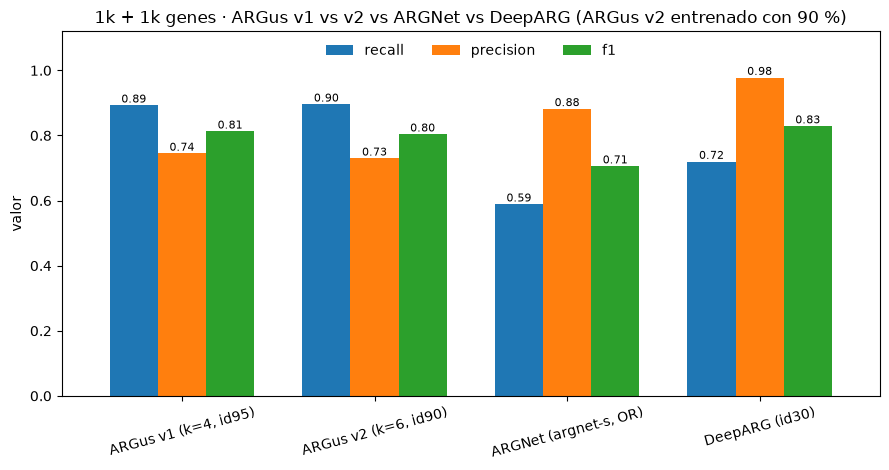

In [ ]:
# ============ CELDA 10: gráfica ============
import matplotlib.pyplot as plt
ax = res.plot.bar(figsize=(9, 4.8), rot=15, width=0.75)
ax.set_ylim(0, 1.12); ax.set_ylabel("valor")
ax.set_title(f"1k + 1k genes · ARGus v1 vs v2 vs ARGNet vs DeepARG (ARGus v2 entrenado con {PCT} %)")
ax.legend(loc="upper center", ncol=3, frameon=False)
for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=8)
plt.tight_layout(); plt.savefig(SALIDA / f"comparacion_{ETIQUETA_CORRIDA}.png", dpi=200); plt.show()

In [ ]:
# ============ CELDA EXTRA: validación cruzada 10-fold (mismo formato que el primer modelo) ============
from sklearn.metrics import classification_report

t0 = time.time()
y_pool = pool[col_lab].values
g_pool = pool["gen"].values
X_pool = matriz(pool[col_seq].astype(str).values)
print("X_pool:", X_pool.shape, f"{X_pool.nbytes/1e9:.2f} GB", f"({time.time()-t0:.0f}s)")

skf = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED)
rng_cv = np.random.default_rng(SEED)
oof_p = np.zeros(len(y_pool))            # probabilidad fuera de pliegue
oof_pred = np.zeros(len(y_pool), dtype=int)
rec, pre, f1s, aucs = [], [], [], []

for i, (tr_i, va_i) in enumerate(skf.split(X_pool, y_pool, g_pool), 1):
    assert not set(g_pool[tr_i]) & set(g_pool[va_i]), "FUGA: un gen en train y validación"
    pos_i = tr_i[y_pool[tr_i] == 1]
    neg_i = tr_i[y_pool[tr_i] == 0]
    neg_ds = rng_cv.choice(neg_i, size=len(pos_i), replace=False)      # undersampling SOLO en el train del pliegue
    bal = np.concatenate([pos_i, neg_ds]); rng_cv.shuffle(bal)
    m = RandomForestClassifier(n_estimators=N_ARBOLES, n_jobs=-1, random_state=SEED)
    m.fit(X_pool[bal], y_pool[bal])
    p = m.predict_proba(X_pool[va_i])[:, 1]
    pr = (p >= 0.5).astype(int)
    oof_p[va_i] = p; oof_pred[va_i] = pr
    rec.append(recall_score(y_pool[va_i], pr)); pre.append(precision_score(y_pool[va_i], pr, zero_division=0))
    f1s.append(f1_score(y_pool[va_i], pr)); aucs.append(roc_auc_score(y_pool[va_i], p))
    print(f"pliegue {i}/10  recall={rec[-1]:.3f}  auc={aucs[-1]:.3f}")

print("\n=== PROMEDIOS (10-fold) ===")
print(f"Recall:    {np.mean(rec):.3f} +/- {np.std(rec):.3f}")
print(f"Precision: {np.mean(pre):.3f} +/- {np.std(pre):.3f}")
print(f"F1:        {np.mean(f1s):.3f} +/- {np.std(f1s):.3f}")
print(f"AUC-ROC:   {np.mean(aucs):.3f} +/- {np.std(aucs):.3f}")

print("\n=== ACUMULADO de los 10 pliegues (por fragmento) ===")
cm = confusion_matrix(y_pool, oof_pred)
print("Matriz de confusión:")
print("               Predijo NEG  Predijo POS")
print(f"  Real NEG (0)   {cm[0,0]:>9,}  {cm[0,1]:>11,}")
print(f"  Real POS (1)   {cm[1,0]:>9,}  {cm[1,1]:>11,}\n")
print(classification_report(y_pool, oof_pred, digits=3))
print(f"AUC-ROC: {roc_auc_score(y_pool, oof_p):.3f}")

# --- extra: mismo resultado agregado a nivel gen (ARG si algún fragmento lo es) ---
dg = pd.DataFrame({"gen": g_pool, "y": y_pool, "pred": oof_pred, "p": oof_p}).groupby("gen").agg(
    y=("y", "max"), pred=("pred", "max"), p=("p", "max"))
print("\n=== NIVEL GEN (fuera de pliegue, regla 'any') ===", len(dg), "genes")
print({k: round(v, 3) for k, v in metricas(dg.y, dg.pred, dg.p).items()})
print(confusion_matrix(dg.y, dg.pred))
print(f"Tiempo total: {time.time()-t0:.0f}s")

NameError: name 'time' is not defined